# Qwen3.5-4B｜视频空间理解与关键帧选择（2秒 / 8帧）

**目的：** 验证模型的**真实视频输入通路**、运动方向与相对位置变化判断，以及根据回答提取并展示关键帧。

- 主实验给模型传入一个 `type="video"` 的 **8帧序列**（不是8张互不相关的图片），每一帧编号 `F01~F08`。
- 代码可自动生成2秒合成车辆视频作**通路/空间判断对照**；也可以换成真实视频，默认只截取其中2秒。
- 输出包含：全部8帧预览、模型完整回答、模型指定的关键帧图片、JSON日志。**模型不会生成新的画面；关键帧是从原视频采样帧中提取的。**
- 合成视频的参考答案：红车 R 从蓝车 B 的**左上方**移动到**右上方**；B 位置不动。只在看见真实视频内容时才能给这一答案。

视频输入参考：[Transformers 多模态聊天模板](https://huggingface.co/docs/transformers/main/chat_templating_multimodal) / [Qwen3.5 Transformers 视频测试](https://github.com/huggingface/transformers/blob/main/tests/models/qwen3_5/test_modeling_qwen3_5.py)。

## 1. 导入环境与设置目录

In [1]:
import json, re, time, shutil, urllib.request
from pathlib import Path
import cv2
import numpy as np
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
import torch
from transformers import AutoProcessor, AutoModelForMultimodalLM

# 如果在 VLM-test/evaluation/几何理解简单测试/ 下运行，自动以当前目录保存
HERE = Path.cwd().resolve()
OUT_DIR = HERE / 'qwen_video_outputs'
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_ID = 'Qwen/Qwen3.5-4B'
VIDEO_KIND = 'demo'  # 'demo' / 'local' / 'intel'
LOCAL_VIDEO_PATH = '/path/to/your_video.mp4'  # VIDEO_KIND='local' 时填写
CLIP_START_SEC = 0.0  # 真实视频可修改起始秒数
CLIP_SECONDS = 2.0
N_FRAMES = 8
MAX_IMAGE_SIDE = 960

print('输出目录:', OUT_DIR)

/home/20261024_1/.local/share/mamba/envs/vlm-test/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


输出目录: /home/20261024_1/Workspace/qyh/VLM-test/evaluation/几何理解简单测试/qwen_video_outputs


## 2. 可选：生成2秒合成测试视频（用于核对输入与空间推理）

In [2]:
DEMO_VIDEO = OUT_DIR / 'qwen_spatial_demo_2s.mp4'

def make_demo_video(path: Path, fps=12, duration=2):
    width, height = 800, 450
    writer = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*'mp4v'), fps, (width, height))
    if not writer.isOpened():
        raise RuntimeError('无法创建 MP4，请检查 OpenCV 是否支持 mp4v')
    def draw_car(d, x, y, color, name):
        x, y = int(x), int(y)
        d.rounded_rectangle((x-53, y-27, x+53, y+27), radius=13, fill=(15,20,25))
        d.rounded_rectangle((x-48, y-23, x+48, y+23), radius=12,
                            fill=color, outline=(238,241,244), width=2)
        d.rounded_rectangle((x-15,y-16,x+24,y+16), radius=8, fill=(21,44,53))
        d.rectangle((x+44,y-12,x+49,y-5), fill=(255,246,160))
        d.rectangle((x+44,y+5,x+49,y+12), fill=(255,246,160))
        d.text((x-6,y-8), name, fill='white', stroke_width=1, stroke_fill='black')
    for i in range(int(fps*duration)):
        im = Image.new('RGB', (width, height), (33,47,54))
        d = ImageDraw.Draw(im)
        d.rectangle((0,40,width,410), fill=(52,63,68))
        d.line((0,40,width,40), fill='white', width=4)
        d.line((0,409,width,409), fill='white', width=4)
        for x in range(18,width,100):
            d.rectangle((x,220,x+56,225), fill=(219,219,197))
        draw_car(d, 440, 305, (33,124,241), 'B')  # 蓝车：静止
        draw_car(d, 225, 305, (227,170,39), 'Y')  # 黄车：干扰项
        red_x = 122 + 565*i/(fps*duration-1)
        draw_car(d, red_x, 155, (225,62,54), 'R')  # 红车：从左到右
        writer.write(cv2.cvtColor(np.asarray(im), cv2.COLOR_RGB2BGR))
    writer.release()

if not DEMO_VIDEO.is_file():
    make_demo_video(DEMO_VIDEO)
print('合成视频:', DEMO_VIDEO, '大小:', DEMO_VIDEO.stat().st_size, 'bytes')

合成视频: /home/20261024_1/Workspace/qyh/VLM-test/evaluation/几何理解简单测试/qwen_video_outputs/qwen_spatial_demo_2s.mp4 大小: 51801 bytes


## 3. 选择视频：合成 / 自己的视频 / Intel 公开车辆视频

默认用合成素材。要用自己的视频：改 `VIDEO_KIND='local'` 并填写 `LOCAL_VIDEO_PATH`。想用公开的真实车辆视频：改 `VIDEO_KIND='intel'`，从 [Intel car-detection.mp4](https://github.com/intel-iot-devkit/sample-videos/blob/master/car-detection.mp4) 自动下载；仓库许可为 CC BY 4.0（请保留来源标注）。下载失败时可以先手动下载到本地，再设为 `local`。这一步不改变用户自己的源视频。

In [3]:
INTEL_URL = 'https://raw.githubusercontent.com/intel-iot-devkit/sample-videos/master/car-detection.mp4'
INTEL_VIDEO = OUT_DIR / 'intel_car_detection_original.mp4'

if VIDEO_KIND == 'demo':
    VIDEO_PATH = DEMO_VIDEO
elif VIDEO_KIND == 'local':
    VIDEO_PATH = Path(LOCAL_VIDEO_PATH).expanduser().resolve()
elif VIDEO_KIND == 'intel':
    if not INTEL_VIDEO.exists():
        print('下载 Intel 示例视频（下载原片；下面只截取2秒）...')
        urllib.request.urlretrieve(INTEL_URL, INTEL_VIDEO)
    VIDEO_PATH = INTEL_VIDEO
else:
    raise ValueError('VIDEO_KIND 必须为 demo/local/intel')

if not VIDEO_PATH.is_file():
    raise FileNotFoundError(VIDEO_PATH)
print('视频路径:', VIDEO_PATH)

视频路径: /home/20261024_1/Workspace/qyh/VLM-test/evaluation/几何理解简单测试/qwen_video_outputs/qwen_spatial_demo_2s.mp4


## 4. 精确截取2秒，抽取8个编号帧

不依赖模型自动抽帧：用 OpenCV 先保存本次输入的 **8张帧图片**，然后交给 Qwen 的 `type="video"` 入口。这样 Notebook 预览的就是模型看到的内容，便于核对回答与关键帧编号。

In [4]:
cap = cv2.VideoCapture(str(VIDEO_PATH))
if not cap.isOpened():
    raise RuntimeError('OpenCV 无法打开视频。请先检查 MP4 编码或路径。')
source_fps = float(cap.get(cv2.CAP_PROP_FPS))
source_total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
if source_fps <= 0 or source_total <= 0:
    raise RuntimeError('无法读取有效 FPS / 总帧数')
start_frame = int(round(CLIP_START_SEC * source_fps))
if start_frame >= source_total:
    raise ValueError('CLIP_START_SEC 超出了视频时长')
clip_count = min(int(round(CLIP_SECONDS * source_fps)), source_total - start_frame)
if clip_count < N_FRAMES:
    raise ValueError('所选视频片段少于8帧；请换一段视频或降低 N_FRAMES')

clip_path = OUT_DIR / 'clip_2s.mp4'
frame_dir = OUT_DIR / 'sampled_frames'
frame_dir.mkdir(exist_ok=True)
cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)
first_ok, first = cap.read()
if not first_ok:
    raise RuntimeError('首帧无法解码')
h0,w0 = first.shape[:2]
scale = min(1.0, MAX_IMAGE_SIDE/max(w0,h0))
w,h = max(2,(int(w0*scale)//2)*2), max(2,(int(h0*scale)//2)*2)
writer = cv2.VideoWriter(str(clip_path), cv2.VideoWriter_fourcc(*'mp4v'), source_fps, (w,h))
if not writer.isOpened():
    raise RuntimeError('2秒视频写入失败：检查 mp4v 编码支持')
cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)
written=0
for _ in range(clip_count):
    ok,frame=cap.read()
    if not ok: break
    if (w,h)!=(w0,h0): frame=cv2.resize(frame,(w,h),interpolation=cv2.INTER_AREA)
    writer.write(frame)
    written+=1
cap.release()
writer.release()
if written < N_FRAMES:
    raise RuntimeError(f'实际仅成功读取{written}帧')

# 按本次2秒片段均匀采样8帧；把帧序号/时间打印在每张帧的左上角
sample_indices = np.rint(np.linspace(0,written-1,N_FRAMES)).astype(int).tolist()
clip_cap = cv2.VideoCapture(str(clip_path))
frame_paths=[]
frame_times=[]
for j, idx in enumerate(sample_indices, 1):
    clip_cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok,frame=clip_cap.read()
    if not ok: raise RuntimeError(f'第 {idx} 帧读取失败')
    t=idx/source_fps
    cv2.rectangle(frame,(8,8),(170,40),(12,12,12),-1)
    cv2.putText(frame,f'F{j:02d}  t={t:.2f}s',(14,31),
                cv2.FONT_HERSHEY_SIMPLEX,0.62,(255,255,255),2,cv2.LINE_AA)
    fp=frame_dir / f'F{j:02d}.png'
    cv2.imwrite(str(fp),frame)
    frame_paths.append(str(fp))
    frame_times.append(round(t,3))
clip_cap.release()

print('2秒片段:', clip_path, '长度约:', round(written/source_fps,3),'秒')
print('采样时间:',frame_times)
print('帧编号:',[Path(p).stem for p in frame_paths])

2秒片段: /home/20261024_1/Workspace/qyh/VLM-test/evaluation/几何理解简单测试/qwen_video_outputs/clip_2s.mp4 长度约: 2.0 秒
采样时间: [0.0, 0.25, 0.583, 0.833, 1.083, 1.333, 1.667, 1.917]
帧编号: ['F01', 'F02', 'F03', 'F04', 'F05', 'F06', 'F07', 'F08']


## 5. 预览这8帧（此处显示的就是模型接收到的视觉内容）

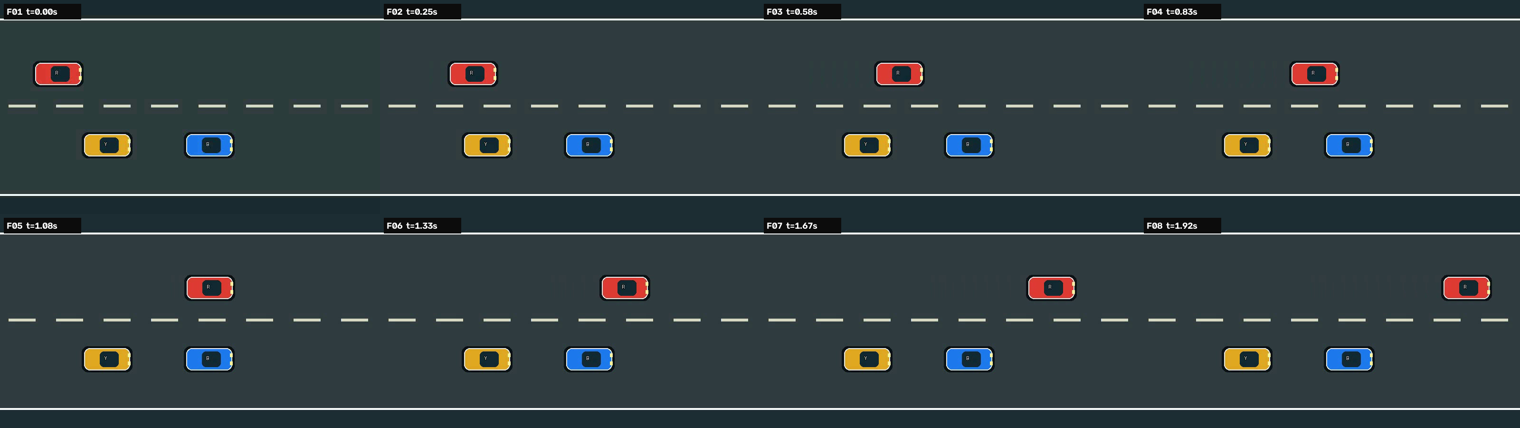

8帧总览: /home/20261024_1/Workspace/qyh/VLM-test/evaluation/几何理解简单测试/qwen_video_outputs/all_8_frames.jpg


In [5]:
thumb_w=380
thumb_h=round(h*thumb_w/w)
sheet=Image.new('RGB',(thumb_w*4, thumb_h*2), '#f8f8f8')
for i,p in enumerate(frame_paths):
    im=Image.open(p).convert('RGB').resize((thumb_w,thumb_h))
    sheet.paste(im,((i%4)*thumb_w,(i//4)*thumb_h))
contact_path=OUT_DIR/'all_8_frames.jpg'
sheet.save(contact_path,quality=90)
display(sheet)
print('8帧总览:',contact_path)

## 6. 加载 Qwen3.5-4B（沿用你已验证过的原生 Transformers 方式）

In [6]:
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForMultimodalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.bfloat16,
    device_map='auto',
)
model.eval()
print('模型:', MODEL_ID, '设备:', model.device)

Loading weights: 100%|██████████| 723/723 [00:02<00:00, 284.27it/s]


模型: Qwen/Qwen3.5-4B 设备: cuda:0


## 7. 构造时序/空间推理问题

- `demo` 用明确的 R/B 车辆关系来做可核验测试；正确的关键结论是**R 从 B 左侧移动到 B 右侧，且始终在 B 上方**。
- `local/intel` 用通用问题，防止对真实视频询问不存在的红蓝车。
- 坐标约定为**图像坐标系**，避免把相机运动和物体真实运动混为一谈。

In [7]:
PROMPT_DEMO = """
请根据按时间顺序排列的8帧视频回答。每帧左上角标记为F01到F08。
固定采用整个图像的坐标系：左是图像左边，上是图像上边。不得依据车辆朝向改变方向定义。

请观察红色车R和蓝色车B：
1. 在F01，红车R相对蓝车B位于什么方位？
2. 在F08，红车R相对蓝车B位于什么方位？
3. 红车R的图像运动方向是什么？蓝车B是否明显移动？
4. 它们的左右次序是否在视频过程中发生改变？请给出图像证据。
5. 从F01~F08中选择最多3个最能证明你判断的关键帧，指出序号及理由。
只能根据画面推断，不要编造速度或实际米数。

请只输出一个JSON对象，格式如下：
{"initial_relation":"...","final_relation":"...","red_motion":"...",
 "blue_motion":"...","relative_order_changed":"是/否/不确定",
 "keyframe_ids":[],"keyframe_reasons":["...","...","..."]}
"""

PROMPT_REAL = """
请根据按时间顺序排列的8帧视频回答，每帧左上角标记为F01到F08。
固定采用图像坐标系，左、右、上、下都相对于整个画面。
1. 识别一名/个最明显的运动目标A，并寻找一个较稳定的参照目标B（如果没有则说明无法判断）。
2. A在F01与F08分别位于什么图像位置？相对B的位置是否变化？
3. A在图像坐标系中的运动方向是什么？镜头运动是否可能影响判断？
4. 从F01~F08选择最多3个最有代表性的关键帧，说明能看出什么位置变化。
5. 无法根据画面确定的内容请明确回答“不确定”，不得编造真实世界距离或速度。

只输出一个JSON对象：
{"object_A":"...","object_B":"...","initial_relation":"...",
 "final_relation":"...","motion_direction":"...","camera_motion":"...",
 "keyframe_ids":[],"keyframe_reasons":["...","...","..."]}
"""

question = PROMPT_DEMO if VIDEO_KIND == 'demo' else PROMPT_REAL
print(question)


请根据按时间顺序排列的8帧视频回答。每帧左上角标记为F01到F08。
固定采用整个图像的坐标系：左是图像左边，上是图像上边。不得依据车辆朝向改变方向定义。

请观察红色车R和蓝色车B：
1. 在F01，红车R相对蓝车B位于什么方位？
2. 在F08，红车R相对蓝车B位于什么方位？
3. 红车R的图像运动方向是什么？蓝车B是否明显移动？
4. 它们的左右次序是否在视频过程中发生改变？请给出图像证据。
5. 从F01~F08中选择最多3个最能证明你判断的关键帧，指出序号及理由。
只能根据画面推断，不要编造速度或实际米数。

请只输出一个JSON对象，格式如下：
{"initial_relation":"...","final_relation":"...","red_motion":"...",
 "blue_motion":"...","relative_order_changed":"是/否/不确定",
 "keyframe_ids":[],"keyframe_reasons":["...","...","..."]}



## 8. 真正的视频输入 + 推理

下面**不是** 8 次单帧推理，而是将8个帧路径作为**同一个 `type="video"` 输入**。输出会检查 `pixel_values_videos`、`video_grid_thw` 是否存在，以验证走了视频路径。

如果 `apply_chat_template` 在你的环境报错，请先核对 Transformers 版本和 `av` / `torchcodec` 安装；`vlm-test` 仓库锁定的依赖包含 `opencv-python-headless` 和 `av`。此处不启用 Thinking，优先检查视频通路是否正常。

In [8]:
messages=[{
    'role':'user',
    'content': [
        {'type':'video', 'path':frame_paths},  # 核心：视频，而不是多张独立 image
        {'type':'text', 'text':question},
    ],
}]

inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors='pt',
    enable_thinking=False,
    do_sample_frames=False,
)
print('输入键:', list(inputs.keys()))
assert 'pixel_values_videos' in inputs, '未形成视频张量，请检查帧列表输入格式和Transformers版本'
print('video_grid_thw:',inputs.get('video_grid_thw'))
inputs=inputs.to(model.device)

seed=42
torch.manual_seed(seed)
if torch.cuda.is_available(): torch.cuda.synchronize()
t0=time.perf_counter()
with torch.inference_mode():
    outputs=model.generate(
        **inputs,
        max_new_tokens=900,
        do_sample=True,
        temperature=0.7,
        top_p=0.8,
        top_k=20,
        repetition_penalty=1.05,
    )
if torch.cuda.is_available(): torch.cuda.synchronize()
elapsed=time.perf_counter()-t0
new_ids=outputs[0][inputs['input_ids'].shape[-1]:]
answer=processor.decode(new_ids,skip_special_tokens=True,clean_up_tokenization_spaces=False)
print('\n===== 模型回答 =====\n',answer)
print(f'\n推理耗时: {elapsed:.2f}s; 新Token: {new_ids.numel()}')
if new_ids.numel()>=900: print('警告：输出触及Token上限，可能被截断')

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Qwen3VL video processing does not apply the per-frame pixel cap the reference implementation (qwen-vl-utils) applies, so some videos cost far more tokens than they would there. In v5.22 the capped behavior will become the default and `cap_pixels_per_frame` will be removed. Pass `cap_pixels_per_frame=True` to adopt the reference behavior now, or `False` to keep the current behavior and silence this warning.
[transformers] Qwen3VL requires frame timestamps to construct prompts, but the `fps` of the input video could not be inferred. Probably `video_metadata` was missing from inputs and you passed pre-sampled frames. Defaulting to `fps=24`. Please provide `video_metadata` for more accurate results.


输入键: ['input_ids', 'attention_mask', 'mm_token_type_ids', 'pixel_values_videos', 'video_grid_thw']
video_grid_thw: tensor([[ 4, 28, 50]])

===== 模型回答 =====
 ```json
{
    "initial_relation": "左上",
    "final_relation": "右上",
    "red_motion": "向右移动",
    "blue_motion": "无明显移动",
    "relative_order_changed": "是",
    "keyframe_ids": [
        "F01",
        "F03",
        "F07"
    ],
    "keyframe_reasons": [
        "F01显示红车R位于蓝车B的左侧且偏上方",
        "F03显示红车R已越过蓝车B，位于其右侧",
        "F07显示红车R完全移动到蓝车B的右上方，证明两者左右次序发生了变化"
    ]
}
```


推理耗时: 5.25s; 新Token: 168


## 9. 解析模型**实际选择**的关键帧，输出图片与日志

若没有解析到 `keyframe_ids`，只报告未解析成功，不会把程序预设的首中末帧冒充为模型选取。

模型选出的关键帧: ['F01', 'F03', 'F07']
F01: 0.00s -> /home/20261024_1/Workspace/qyh/VLM-test/evaluation/几何理解简单测试/qwen_video_outputs/model_selected_keyframes/F01.png


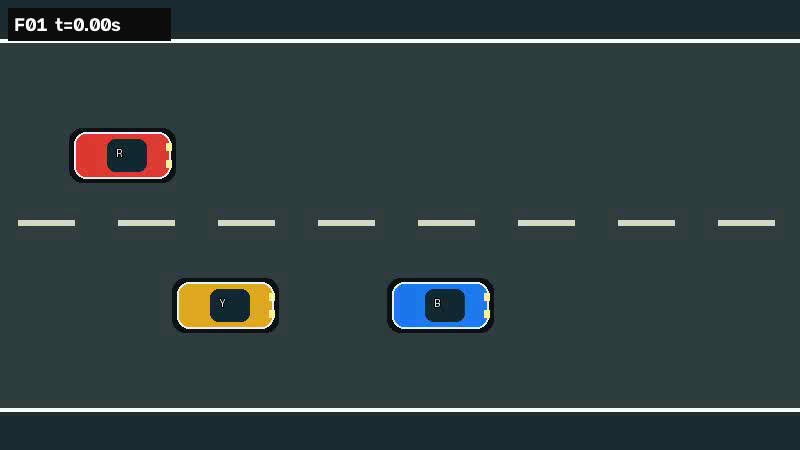

F03: 0.58s -> /home/20261024_1/Workspace/qyh/VLM-test/evaluation/几何理解简单测试/qwen_video_outputs/model_selected_keyframes/F03.png


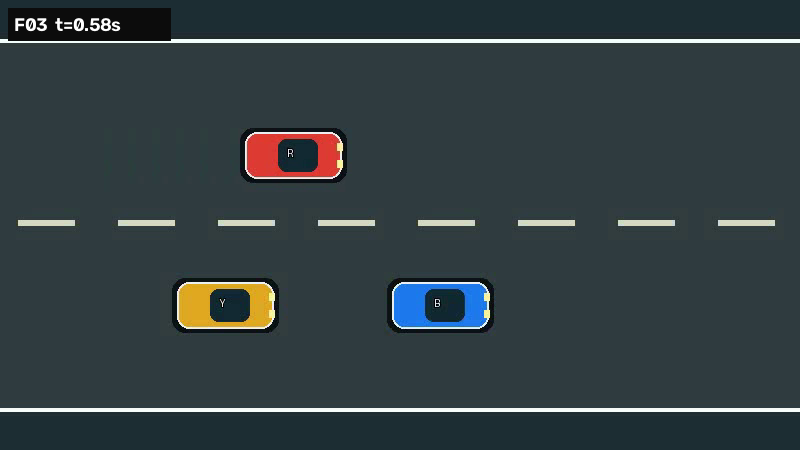

F07: 1.67s -> /home/20261024_1/Workspace/qyh/VLM-test/evaluation/几何理解简单测试/qwen_video_outputs/model_selected_keyframes/F07.png


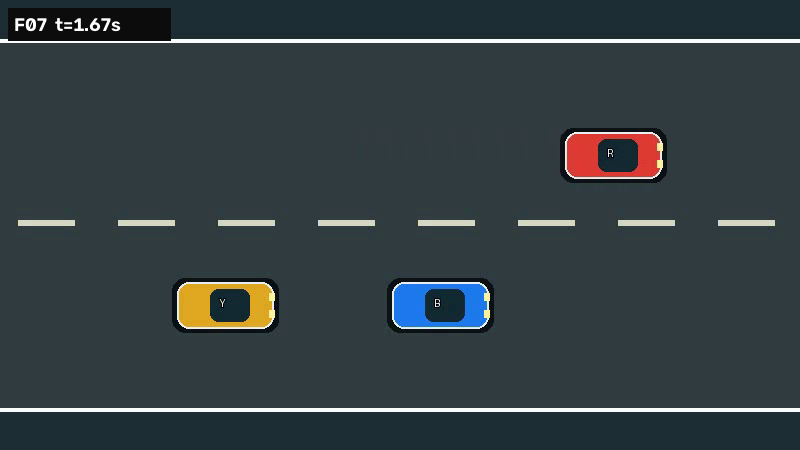

结果JSON: /home/20261024_1/Workspace/qyh/VLM-test/evaluation/几何理解简单测试/qwen_video_outputs/result_video_spatial.json


In [9]:
def extract_json_object(text):
    text=text.rsplit('</think>',1)[-1]
    decoder=json.JSONDecoder()
    for m in re.finditer(r'\{',text):
        try:
            obj,_=decoder.raw_decode(text[m.start():])
            if isinstance(obj,dict): return obj
        except json.JSONDecodeError:
            continue
    return None

parsed=extract_json_object(answer)
chosen=[]
if isinstance(parsed,dict):
    raw_ids=parsed.get('keyframe_ids',[])
    if isinstance(raw_ids,list):
        for v in raw_ids:
            if isinstance(v,(int,str)):
                try: idx=int(str(v).upper().replace('F',''))
                except ValueError: continue
                if 1<=idx<=len(frame_paths) and idx not in chosen:
                    chosen.append(idx)
                if len(chosen)==3: break

if not chosen:
    print('模型没有输出可解析的关键帧编号；保留原始回答，不捏造关键帧。')
else:
    keyframes_out=OUT_DIR/'model_selected_keyframes'
    keyframes_out.mkdir(exist_ok=True)
    print('模型选出的关键帧:', [f'F{i:02d}' for i in chosen])
    for i in chosen:
        src=Path(frame_paths[i-1])
        dst=keyframes_out/src.name
        shutil.copy2(src,dst)
        print(f'F{i:02d}: {frame_times[i-1]:.2f}s -> {dst}')
        display(Image.open(dst))

log={'model':MODEL_ID,'source_video':str(VIDEO_PATH),'clip_path':str(clip_path),
     'frame_times':frame_times,'input_kind':'type=video, path=list[8 frames]',
     'prompt':question,'answer':answer,'parsed':parsed,
     'model_selected_frame_ids':chosen,'elapsed_s':elapsed,'generated_tokens':int(new_ids.numel())}
log_path=OUT_DIR/'result_video_spatial.json'
log_path.write_text(json.dumps(log,ensure_ascii=False,indent=2),encoding='utf-8')
print('结果JSON:',log_path)

## 10. 可选：直接输入 MP4 文件做“原生视频路径”冒烟测试

主实验的帧列表已经是 Qwen 的 `video` 输入。这个可选单元格再把2秒 MP4 文件路径直接交给模型，使用 `num_frames=8`。**注意：** 两种视频加载方式的精确采样帧可能略有差异；要准确复盘关键帧编号，请以第8~9单元格的编号帧实验为准。

In [13]:
RUN_RAW_MP4_CHECK=True  # 需要时改成 True
if RUN_RAW_MP4_CHECK:
    raw_messages=[{'role':'user','content':[
        {'type':'video','path':str(clip_path)},
        {'type':'text','text':'只用一句中文描述视频中最明显的运动变化。'},
    ]}]
    raw_inputs=processor.apply_chat_template(
        raw_messages, add_generation_prompt=True, tokenize=True,
        return_dict=True, return_tensors='pt', enable_thinking=False,
        # num_frames=8,
    )
    print('视频输入键:',list(raw_inputs.keys()))
    assert 'pixel_values_videos' in raw_inputs
    with torch.inference_mode():
        raw_output=model.generate(**raw_inputs.to(model.device),max_new_tokens=150,do_sample=False)
    print(processor.decode(raw_output[0][raw_inputs['input_ids'].shape[-1]:],skip_special_tokens=True))

视频输入键: ['input_ids', 'attention_mask', 'mm_token_type_ids', 'pixel_values_videos', 'video_grid_thw']
视频中，红色汽车从左侧向右侧移动，而黄色和蓝色汽车保持静止。



In [21]:

import cv2
import re
import json
import torch
from pathlib import Path
from PIL import Image
from IPython.display import display

# 1. 读取原视频元数据
cap = cv2.VideoCapture(str(clip_path))
assert cap.isOpened(), "视频无法打开"

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration = total_frames / fps

cap.release()

print(f"原始帧数: {total_frames}")
print(f"原始 FPS: {fps:.2f}")
print(f"视频时长: {duration:.2f}s")

# 2. 让模型自主选择重要时刻
question = f"""
请完整观察这段视频，并结合所有时间上的视觉变化，
从整个视频中选择最重要的1个关键帧。

任务目标：找到红车距离蓝车最近的那一帧。
任务要求：选择最符合目标的那一帧。

输出JSON：
{{
  "summary": "对视频运动过程的总结",
  "keyframes": [
    {{"timestamp": 0.0, "reason": "选择原因"}}
  ]
}}

timestamp 是关键帧在原视频中的时间，单位为秒。
最多选择1帧。只输出JSON。
"""

messages = [{
    "role": "user",
    "content": [
        {"type": "video", "path": str(clip_path)},
        {"type": "text", "text": question},
    ],
}]

# 3. 关键：禁用自动帧采样
inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
    enable_thinking=False,
    do_sample_frames=False,
)

assert "pixel_values_videos" in inputs

# Qwen3.5 的视频时序 patch 默认合并2帧
temporal_patch = getattr(
    processor.video_processor,
    "temporal_patch_size",
    2,
)

model_frames = (
    int(inputs["video_grid_thw"][:, 0].sum().item())
    * temporal_patch
)

print(f"模型预处理覆盖的帧数: {model_frames}")

# 允许最后一帧为了时序 patch 对齐被重复填充
assert total_frames <= model_frames < total_frames + temporal_patch, (
    "帧数不匹配，请检查视频预处理配置"
)

# 4. 模型推理
inputs = inputs.to(model.device)

with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        max_new_tokens=512,
        do_sample=True,
        temperature=0.7,
        top_p=0.8,
        top_k=20,
        repetition_penalty=1.05,
    )

answer = processor.decode(
    outputs[0][inputs["input_ids"].shape[-1]:],
    skip_special_tokens=True,
).strip()

print("模型回答：")
print(answer)

# 5. 根据模型选择的时间戳提取真实图片
match = re.search(r"\{[\s\S]*\}", answer)
assert match, "模型未输出JSON"

result = json.loads(match.group())

save_dir = Path("qwen_video_outputs/full_video_keyframes")
save_dir.mkdir(parents=True, exist_ok=True)

cap = cv2.VideoCapture(str(clip_path))

try:
    for i, item in enumerate(result["keyframes"][:3]):
        t = float(item["timestamp"])
        if not 0 <= t < duration:
            print(f"跳过非法时间戳: {t}")
            continue

        frame_idx = min(
            round(t * fps),
            total_frames - 1,
        )

        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
        ok, frame = cap.read()

        if not ok:
            print(f"无法读取第 {frame_idx} 帧")
            continue

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image = Image.fromarray(frame)

        output_path = save_dir / f"keyframe_{i+1}.png"
        image.save(output_path)

        print(f"\n关键帧 {i+1}: {t:.3f}s")
        print("原因:", item["reason"])
        display(image)
finally:
    cap.release()

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


原始帧数: 24
原始 FPS: 12.00
视频时长: 2.00s
模型预处理覆盖的帧数: 24
模型回答：
```json
{
  "summary": "视频中，红车（R）在上方车道向右行驶，黄车（Y）和蓝车（B）在下方车道静止。红车与蓝车的距离随时间逐渐减小，直到它们几乎并排。",
  "keyframes": [
    {
      "timestamp": 2.0,
      "reason": "在这一帧中，红车已经行驶到最右侧，与蓝车的位置最为接近，距离最小。"
    }
  ]
}
```
跳过非法时间戳: 2.0


## 11. 可选：单帧对照（验证运动判断是否真正利用了前后帧）

In [22]:
RUN_SINGLE_FRAME_CONTROL = True  # 需要时改为 True
if RUN_SINGLE_FRAME_CONTROL:
    single_question = (
        '你只看到视频的最后一帧静态图片。'
        '仅凭这张图能否确定红色车R此前向左还是向右运动？'
        '请回答能/不能，并说明理由；不要猜测。'
    )
    single_messages=[{'role':'user','content':[
        {'type':'image','path':frame_paths[-1]},
        {'type':'text','text':single_question},
    ]}]
    single_inputs=processor.apply_chat_template(
        single_messages,add_generation_prompt=True,tokenize=True,
        return_dict=True,return_tensors='pt',enable_thinking=False,
    ).to(model.device)
    with torch.inference_mode():
        single_outputs=model.generate(
            **single_inputs,max_new_tokens=200,do_sample=False)
    print(processor.decode(
        single_outputs[0][single_inputs['input_ids'].shape[-1]:],
        skip_special_tokens=True))

不能。

理由：仅凭最后一帧静态图片，无法确定红色车R此前是向左还是向右运动。因为静态图像只展示了某一时刻的位置和状态，不包含时间序列信息或运动轨迹。要判断其此前运动方向，需要连续多帧图像以观察其位置变化趋势，而单帧无法提供这种动态信息。



## 12. 总结
总体评价：Qwen3.5-4B 能够正常接收视频，理解简单的目标运动及整体空间关系变化，但在精细时序定位、关键帧选择及时间戳准确性方面存在明显不足。

一、各项测试结果

① 8帧视频空间理解	基本成功	正确判断红车向右移动、蓝车静止，以及红车从蓝车左上方移动至右上方。

② 8帧关键帧选择	部分成功	选择 F01、F03、F07，但错误声称 F03 中红车已经超过蓝车。实际上 F03 时红车仍在蓝车左侧。

③ 原生 MP4 视频输入	成功	正确识别红车从左向右运动、黄车和蓝车保持静止，说明原生视频输入通路正常。

④ 完整视频关键帧选择	失败	成功处理24帧视频，但将红车距离蓝车最近的时刻错误判断为2.0秒，导致关键帧无法提取。

二、值得关注的现象
1. 基础时序空间理解能力较好，但精细时序推理不足。
模型能够从连续画面中正确识别车辆的运动方向、静止状态和初末空间关系。
但在判断关系具体何时发生变化时，出现明显错误。例如 F03（0.583秒）中红车仍处于蓝车左侧，模型却认为其已经越过蓝车。
这表明模型能够理解整体运动趋势，但未必能准确定位变化发生的时刻。

2. 完整视频输入成功，不代表关键帧选择正确。完整视频实验中：
- 原始视频为24帧、12 FPS、2秒。
- 预处理覆盖24帧，说明这次没有被人为限制为8帧。
- 模型输出了关键帧时间戳，但选择结果错误。
根据合成视频的真实车辆位置，红车距离蓝车最近的时刻约为 1.083秒（第14帧，按1开始编号），此时两车在水平方向上基本对齐。
但模型选择了2.0秒，并认为红车在最右侧时距离蓝车最近。这不仅是时间定位错误，也说明其对目标间距离变化的判断存在问题。
此外，2.0秒是视频结束边界，不对应实际存在的帧（最后一帧约为1.917秒），因此程序拒绝提取。这里既有模型选错时间的问题，也有输出时间戳缺乏有效范围约束的问题。

3. 关键帧选择存在“理由合理，但证据错误”的现象。
模型能够生成结构完整的 JSON，并为关键帧提供看似合理的选择理由。
但 F03 的理由与实际画面不符，完整视频实验也没有选中真正的距离最小帧。
因此，模型能够解释为什么选择某帧，并不意味着它真的找到了满足条件的帧。

三、核心结论
1. 视频输入能力得到验证。 Qwen3.5-4B 可以通过原生视频接口处理连续帧，完整视频实验也成功处理了24帧。
2. 基础运动理解能力存在。 模型能够正确识别明显的运动方向和整体空间关系变化。
3. 精细时序定位能力不足。 对空间关系改变的具体时刻、物体距离最小的时刻等判断不可靠。
4. 任务驱动的关键帧选择尚不可靠。 模型能按要求输出帧编号或时间戳，但选择结果与实际视频内容可能不一致。

四、最终判断
Qwen3.5-4B 已具备基础的视频时序理解能力，但尚不能可靠地根据复杂空间条件自主选择关键帧。

相比之前的静态图像测试，这次实验表明模型能够利用连续视觉信息理解整体运动过程，但一旦任务涉及精确的时序定位、空间极值比较，其能力便明显下降。

对后续无人机 VLN 研究而言，这意味着：

模型能够大致理解“发生了什么”，但不一定能准确判断“关键事件发生在什么时候、哪一帧最重要”。

这也提示了一个值得继续探索的方向：如何结合视觉目标定位、时序空间推理与任务指令，实现更加准确、可靠的导航关键帧提取。